1. Import library

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

2. Load Data from Kaggle

In [2]:
# Load dataset
df = pd.read_csv(r"C:\Users\ASUS\MAPID_WEBGIS_BOOTCAMP\Labs\Day 6\Task Day 6\archive\Significant_Earthquakes.csv")
df.head()

,Unnamed: 0,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,0,1900-10-09T12:25:00.000Z,57.09,-153.48,NaN,7.86,mw,NaN,NaN,NaN,...,2022-05-09T14:44:17.838Z,"16 km SW of Old Harbor, Alaska",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,pt
1,1,1901-03-03T07:45:00.000Z,36.00,-120.50,NaN,6.40,ms,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,"12 km NNW of Parkfield, California",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,ell
2,2,1901-07-26T22:20:00.000Z,40.80,-115.70,NaN,5.00,fa,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,"6 km SE of Elko, Nevada",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,sjg
3,3,1901-12-30T22:34:00.000Z,52.00,-160.00,NaN,7.00,ms,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,south of Alaska,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe
4,4,1902-01-01T05:20:30.000Z,52.38,-167.45,NaN,7.00,ms,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,"113 km ESE of Nikolski, Alaska",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe


3. Convert data to geoframe

In [3]:
geometry = [Point(xy) for xy in zip(df['longitude'], df['latitude'])]

gdf_gempa = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

4. Reproject and buffer zona bahaya (100 km)

In [4]:
gdf_proj = gdf_gempa.to_crs(epsg=3857)
gdf_proj['geometry'] = gdf_proj.buffer(100000)  # 100 km

gdf_buffer = gdf_proj.to_crs(epsg=4326)

5. Intersect data

In [5]:
def overlay_multiple(gdf_list):
    result = gdf_list[0]
    for gdf_layer in gdf_list[1:]:
        if not gdf_layer.empty:
            result = gpd.overlay(result, gdf_layer, how='intersection')
            result = result[result.is_valid]
    return result

gdf_list = [
    gdf_buffer,
    ]

gdf_intersect = overlay_multiple(gdf_list)

print(f"Jumlah hasil intersect: {len(gdf_intersect)}")
print("Kolom hasil intersect:", gdf_intersect.columns)

Jumlah hasil intersect: 112185
Kolom hasil intersect: Index(['Unnamed: 0', 'time', 'latitude', 'longitude', 'depth', 'mag',
       'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place',
       'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status',
       'locationSource', 'magSource', 'geometry'],
      dtype='str')


6. Pengkelasan Status gempa

In [6]:
from numpy import place


def kategori_mag(mag):
    if mag >= 6:
        return "TINGGI"
    elif mag >= 5:
        return "SEDANG"
    else:
        return "RENDAH"

gdf_intersect['MAGNITUDE'] = gdf_intersect['mag'].apply(kategori_mag)

def kategori_depth(depth):
    if depth <= 70:
        return "TINGGI"
    elif depth <= 300:
        return "SEDANG"
    else:
        return "RENDAH"

gdf_intersect['DEPTH'] = gdf_intersect['depth'].apply(kategori_depth)

frequency = gdf_intersect['place'].value_counts()
gdf_intersect['FREQ_VAL'] = gdf_intersect['place'].map(frequency)

def kategori_freq(freq):
    if freq >= 50:
        return "TINGGI"
    elif freq >= 20:
        return "SEDANG"
    else:
        return "RENDAH"

gdf_intersect['FREQUENCY'] = gdf_intersect['FREQ_VAL'].apply(kategori_freq)

7. Pemberian skor gempa

In [7]:
def skoring(row):
    skor = 0
    
    skor += {"RENDAH":1, "SEDANG":2, "TINGGI":3}.get(
        str(row.get("MAGNITUDE","")).upper(),0)
    
    skor += {"RENDAH":1, "SEDANG":2, "TINGGI":3}.get(
        str(row.get("DEPTH","")).upper(),0)
    
    skor += {"RENDAH":1, "SEDANG":2, "TINGGI":3}.get(
        str(row.get("FREQUENCY","")).upper(),0)
    
    return skor

gdf_intersect['SKOR_TOTAL'] = gdf_intersect.apply(skoring, axis=1)

8. Pengklasifikasi kelas gempa

In [8]:
gdf_intersect['KELAS_BAHAYA'] = pd.cut(
    gdf_intersect['SKOR_TOTAL'],
    bins=[0,4,6,9],
    labels=['RENDAH','SEDANG','TINGGI'],
    include_lowest=True
)

print(gdf_intersect[['SKOR_TOTAL','KELAS_BAHAYA']].head())

   SKOR_TOTAL KELAS_BAHAYA
0           5       SEDANG
1           5       SEDANG
2           4       RENDAH
3           5       SEDANG
4           5       SEDANG


9. Visualisasi Hasil Skoring & Kesesuaian Lokasi

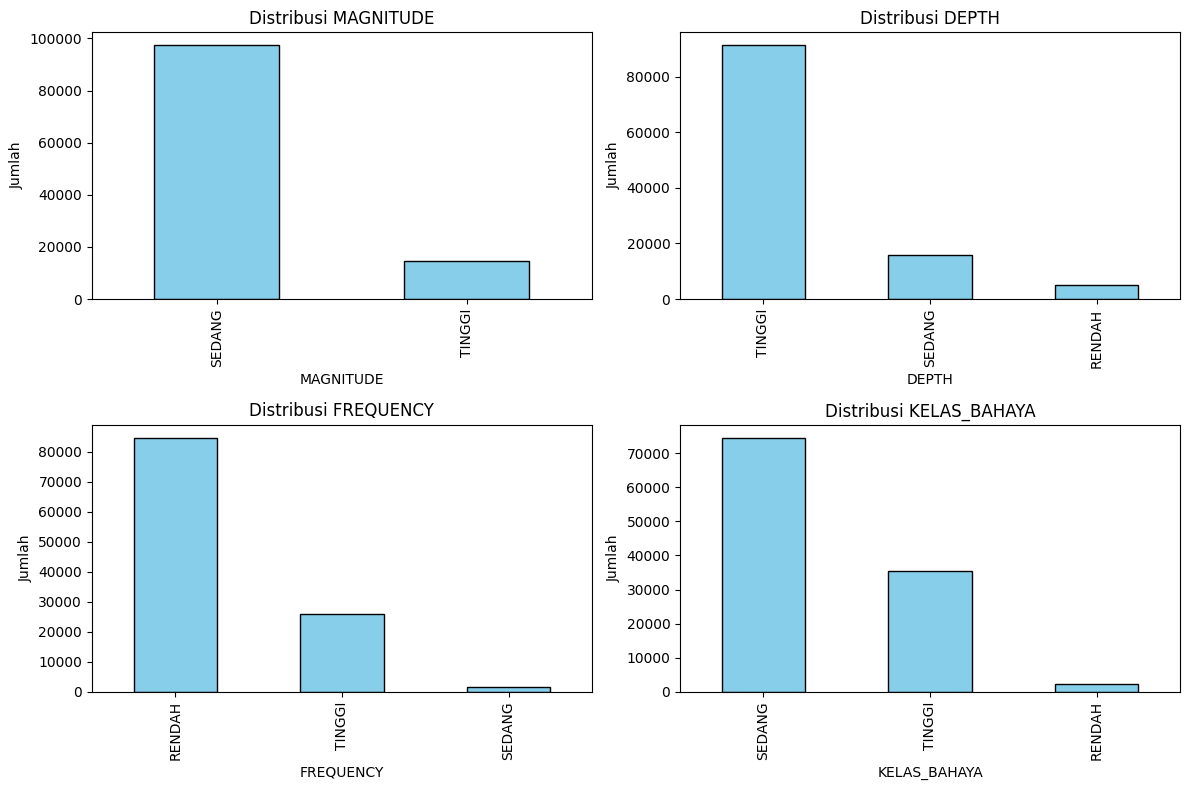

In [9]:
kategori_cols = [
    'MAGNITUDE',
    'DEPTH',
    'FREQUENCY',
    'KELAS_BAHAYA'
]

plt.figure(figsize=(12,8))

for i, col in enumerate(kategori_cols,1):
    if col in gdf_intersect.columns:
        plt.subplot(2,2,i)
        gdf_intersect[col].value_counts().plot(
            kind='bar',
            color='skyblue',
            edgecolor='black'
        )
        plt.title(f'Distribusi {col}')
        plt.xlabel(col)
        plt.ylabel('Jumlah')

plt.tight_layout()
plt.show()

gdf_intersect.to_file("earthquake_risk_final.geojson", driver="GeoJSON")

10. Save & Export data

In [ ]:
risk_country = gdf_intersect.groupby('KELAS_BAHAYA')['SKOR_TOTAL'].mean().reset_index()

risk_country['KELAS_NEGARA'] = pd.cut(
    risk_country['SKOR_TOTAL'],
    bins=[0, 4, 6, 9],
    labels=['RENDAH', 'SEDANG', 'TINGGI'],
    include_lowest=True
)

print(risk_country.head())

  KELAS_BAHAYA  SKOR_TOTAL KELAS_NEGARA
0       RENDAH    4.000000       RENDAH
1       SEDANG    5.828114       SEDANG
2       TINGGI    7.682818       TINGGI
